In [1]:
import glob, importlib, os, subprocess, sys, zipfile

for mod, pkg in [("pydicom", "pydicom")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom
from scipy.ndimage import map_coordinates

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.grid": False,
})

ROOT = "dicom-samples"
if not os.path.isdir(ROOT):
    if not os.path.exists("dicom-samples.zip"):
        try:
            from google.colab import files
            files.upload()
        except Exception:
            raise SystemExit("dicom-samples.zip を、このノートブックと同じフォルダに置いてから、もう一度実行してください")
    zipfile.ZipFile("dicom-samples.zip").extractall(".")

def read_dir(name):
    return [pydicom.dcmread(p) for p in sorted(glob.glob(f"{ROOT}/{name}/**/*.dcm", recursive=True))]

KeyboardInterrupt: 

In [2]:
import glob, importlib, os, subprocess, sys, zipfile

for mod, pkg in [("pydicom", "pydicom")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom
from scipy.ndimage import map_coordinates

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.grid": False,
})

ROOT = "dicom-samples"
if not os.path.isdir(ROOT):
    zipfile.ZipFile("dicom-samples.zip").extractall(".")

def read_dir(name):
    return [pydicom.dcmread(p) for p in sorted(glob.glob(f"{ROOT}/{name}/**/*.dcm", recursive=True))]

print("準備完了")

準備完了


In [3]:
rows = []
for name in ["ct-psma", "pet-psma", "ct-hcc", "seg-hcc", "mr-lgg"]:
    files_ = sorted(glob.glob(f"{ROOT}/{name}/**/*.dcm", recursive=True))
    ds = pydicom.dcmread(files_[0], stop_before_pixels=True)
    rows.append({
        "folder": name, "files": len(files_), "Modality": ds.Modality,
        "SOP Class": ds.SOPClassUID.name,
        "KB/file": os.path.getsize(files_[0]) // 1024,
        "Transfer Syntax": ds.file_meta.TransferSyntaxUID.name,
    })
pd.DataFrame(rows)

,folder,files,Modality,SOP Class,KB/file,Transfer Syntax
0,ct-psma,12,CT,CT Image Storage,515,Explicit VR Little Endian
1,pet-psma,40,PT,Positron Emission Tomography Image Storage,82,Explicit VR Little Endian
2,ct-hcc,36,CT,CT Image Storage,514,Explicit VR Little Endian
3,seg-hcc,1,SEG,Segmentation Storage,4850,Explicit VR Little Endian
4,mr-lgg,6,MR,MR Image Storage,514,Implicit VR Little Endian


In [4]:
import struct

path = sorted(glob.glob(f"{ROOT}/ct-psma/*.dcm"))[0]
raw = open(path, "rb").read()
print("全体のバイト数:", len(raw))
print("先頭128バイトはすべて0か:", raw[:128] == b"\x00" * 128)
print("128〜131バイト目:", raw[128:132])

LONG_VR = {"OB", "OW", "OF", "OD", "SQ", "UN", "UT"}
pos = 132
for _ in range(4):
    group, elem = struct.unpack("<HH", raw[pos:pos + 4])
    vr = raw[pos + 4:pos + 6].decode()
    if vr in LONG_VR:
        (length,) = struct.unpack("<I", raw[pos + 8:pos + 12]); start = pos + 12
    else:
        (length,) = struct.unpack("<H", raw[pos + 6:pos + 8]); start = pos + 8
    value = raw[start:start + length]
    shown = struct.unpack("<I", value)[0] if vr == "UL" else (value.rstrip(b"\x00").decode() if vr == "UI" else value)
    print(f"({group:04X},{elem:04X}) VR={vr} 長さ={length:>3} 値={shown}")
    pos = start + length

全体のバイト数: 528120
先頭128バイトはすべて0か: True
128〜131バイト目: b'DICM'
(0002,0000) VR=UL 長さ=  4 値=210
(0002,0001) VR=OB 長さ=  2 値=b'\x00\x01'
(0002,0002) VR=UI 長さ= 26 値=1.2.840.10008.5.1.4.1.1.2
(0002,0003) VR=UI 長さ= 64 値=1.3.6.1.4.1.14519.5.2.1.290969635085280264448811376476138954865


In [5]:
e = raw[132:144]
print("全体          :", e.hex(" "))
print("グループ(2B)  :", e[0:2].hex(" "), "→", f"0x{struct.unpack('<H', e[0:2])[0]:04X}")
print("要素(2B)      :", e[2:4].hex(" "), "→", f"0x{struct.unpack('<H', e[2:4])[0]:04X}")
print("VR(2B)        :", e[4:6].hex(" "), "→", e[4:6].decode())
print("長さ(2B)      :", e[6:8].hex(" "), "→", struct.unpack("<H", e[6:8])[0], "バイト")
print("値(4B)        :", e[8:12].hex(" "), "→", struct.unpack("<I", e[8:12])[0])

全体          : 02 00 00 00 55 4c 04 00 d2 00 00 00
グループ(2B)  : 02 00 → 0x0002
要素(2B)      : 00 00 → 0x0000
VR(2B)        : 55 4c → UL
長さ(2B)      : 04 00 → 4 バイト
値(4B)        : d2 00 00 00 → 210


In [6]:
ds = pydicom.dcmread(path)
print(ds.file_meta.FileMetaInformationGroupLength)
print(ds.file_meta.TransferSyntaxUID, "=", ds.file_meta.TransferSyntaxUID.name)

for name in ["ct-psma", "mr-lgg"]:
    p = sorted(glob.glob(f"{ROOT}/{name}/**/*.dcm", recursive=True))[0]
    b = open(p, "rb").read()
    meta_len = struct.unpack("<I", b[140:144])[0]
    first = 144 + meta_len
    print(name, b[first:first + 12].hex(" "))

210
1.2.840.10008.1.2.1 = Explicit VR Little Endian
ct-psma 08 00 05 00 43 53 0a 00 49 53 4f 5f
mr-lgg 08 00 05 00 0a 00 00 00 49 53 4f 5f


In [7]:
mr_path = sorted(glob.glob(f"{ROOT}/mr-lgg/**/*.dcm", recursive=True))[0]
mr_ds = pydicom.dcmread(mr_path)
print(mr_ds.file_meta.TransferSyntaxUID, "=", mr_ds.file_meta.TransferSyntaxUID.name)

1.2.840.10008.1.2 = Implicit VR Little Endian


In [8]:
path = sorted(glob.glob(f"{ROOT}/ct-psma/*.dcm"))[0]
raw = open(path, "rb").read()
pos = 132
for _ in range(4):
    group, elem = struct.unpack("<HH", raw[pos:pos + 4])
    vr = raw[pos + 4:pos + 6].decode()
    (length,) = struct.unpack("<H", raw[pos + 6:pos + 8])
    print(f"({group:04X},{elem:04X}) VR={vr} 長さ={length}")
    pos = pos + 8 + length

(0002,0000) VR=UL 長さ=4
(0002,0001) VR=OB 長さ=0
(0002,0000) VR=  長さ=2
(4955,001A) VR=1. 長さ=11826


In [9]:
path = sorted(glob.glob(f"{ROOT}/ct-psma/*.dcm"))[0]
raw = open(path, "rb").read()
pos = 132
for _ in range(4):
    group, elem = struct.unpack("<HH", raw[pos:pos + 4])
    vr = raw[pos + 4:pos + 6].decode()
    if vr in LONG_VR:
        (length,) = struct.unpack("<I", raw[pos + 8:pos + 12]); start = pos + 12
    else:
        (length,) = struct.unpack("<H", raw[pos + 6:pos + 8]); start = pos + 8
    print(f"({group:04X},{elem:04X}) VR={vr} 長さ={length}")
    pos = start + length

(0002,0000) VR=UL 長さ=4
(0002,0001) VR=OB 長さ=2
(0002,0002) VR=UI 長さ=26
(0002,0003) VR=UI 長さ=64


In [10]:
ds = pydicom.dcmread(sorted(glob.glob(f"{ROOT}/pet-psma/*.dcm"))[0])
print(ds.Modality)
print(ds[0x0008, 0x0060].value)
print(ds["Modality"].VR)

print(pydicom.datadict.tag_for_keyword("SliceThickness"))
print(pydicom.datadict.keyword_for_tag(0x00180050), "|", pydicom.datadict.dictionary_description(0x00180050))

PT
PT
CS
1572944
SliceThickness | Slice Thickness


In [11]:
print("PatientSize" in ds)
print(ds.get("PatientSize"))
print(ds.get("PatientSize", "未記録"))
print(ds.PatientWeight)

False
None
未記録
120


In [12]:
rows = [(f"({e.tag.group:04X},{e.tag.element:04X})", e.keyword, e.VR, str(e.value)[:36])
        for e in ds if e.keyword != "PixelData" and e.VR != "SQ" and not e.tag.is_private]
pd.DataFrame(rows, columns=["tag", "keyword", "VR", "value"]).head(14)

,tag,keyword,VR,value
0,"(0008,0005)",SpecificCharacterSet,CS,ISO_IR 192
1,"(0008,0008)",ImageType,CS,"['DERIVED', 'SECONDARY']"
2,"(0008,0012)",InstanceCreationDate,DA,20251013
3,"(0008,0013)",InstanceCreationTime,TM,082417
4,"(0008,0016)",SOPClassUID,UI,1.2.840.10008.5.1.4.1.1.128
5,"(0008,0018)",SOPInstanceUID,UI,1.3.6.1.4.1.14519.5.2.1.315114207666
6,"(0008,0020)",StudyDate,DA,20030402
7,"(0008,0021)",SeriesDate,DA,20030402
8,"(0008,0022)",AcquisitionDate,DA,20030402
9,"(0008,0023)",ContentDate,DA,20030402


In [13]:
phi = [(e.keyword, e.VR, "あり" if str(e.value) else "空") for e in ds if e.VR in ("PN", "DA", "TM", "DT")]
print(pd.DataFrame(phi, columns=["keyword", "VR", "値"]).to_string(index=False))

               keyword VR  値
  InstanceCreationDate DA あり
  InstanceCreationTime TM あり
             StudyDate DA あり
            SeriesDate DA あり
       AcquisitionDate DA あり
           ContentDate DA あり
             StudyTime TM あり
            SeriesTime TM あり
       AcquisitionTime TM あり
           ContentTime TM あり
ReferringPhysicianName PN  空
           PatientName PN あり
      PatientBirthDate DA  空


In [14]:
ct1 = pydicom.dcmread(sorted(glob.glob(f"{ROOT}/ct-psma/*.dcm"))[0])
tags = ["Modality", "PixelSpacing", "SliceThickness", "KVP", "Rows", "Columns"]
rows = []
for kw in tags:
    if kw in ct1:
        e = ct1[kw]
        rows.append((f"({e.tag.group:04X},{e.tag.element:04X})", e.keyword, e.VR, str(e.value)[:36]))
    else:
        rows.append(("—", kw, "—", "未記録"))
pd.DataFrame(rows, columns=["tag", "keyword", "VR", "value"])

,tag,keyword,VR,value
0,"(0008,0060)",Modality,CS,CT
1,"(0028,0030)",PixelSpacing,DS,"[0.9765625, 0.9765625]"
2,"(0018,0050)",SliceThickness,DS,3
3,"(0018,0060)",KVP,DS,100
4,"(0028,0010)",Rows,US,512
5,"(0028,0011)",Columns,US,512


In [15]:
ct1 = pydicom.dcmread(sorted(glob.glob(f"{ROOT}/ct-psma/*.dcm"))[0])
print(ct1.PatientSize)

AttributeError: 'FileDataset' object has no attribute 'PatientSize'

In [16]:
ct1 = pydicom.dcmread(sorted(glob.glob(f"{ROOT}/ct-psma/*.dcm"))[0])
print(ct1.get("PatientSize", "未記録"))

未記録


In [17]:
ct = sorted(read_dir("ct-psma"), key=lambda d: float(d.ImagePositionPatient[2]))
d = ct[len(ct) // 2]
stored = d.pixel_array.astype(float)
slope, intercept = float(d.RescaleSlope), float(d.RescaleIntercept)
hu = stored * slope + intercept
print(f"stored: {stored.min():.0f} 〜 {stored.max():.0f}   slope={slope}  intercept={intercept}")
print(f"HU    : {hu.min():.0f} 〜 {hu.max():.0f}")
print("画像の隅 20×20 画素の平均（体の外の空気）:", round(hu[:20, :20].mean(), 1), "HU")

stored: 0 〜 2328   slope=1.0  intercept=-1024.0
HU    : -1024 〜 1304
画像の隅 20×20 画素の平均（体の外の空気）: -1024.0 HU


In [18]:
body = hu[hu > -300]
print("体（肺以外）の HU の中央値:", round(np.median(body), 1))

体（肺以外）の HU の中央値: -48.0


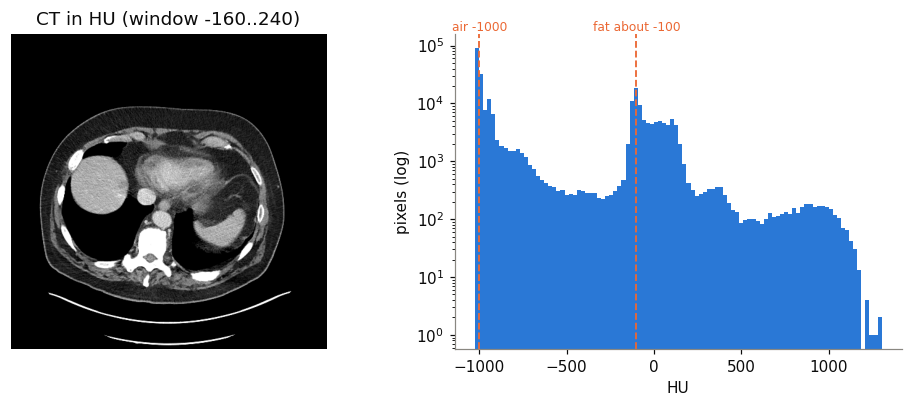

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
ax[0].imshow(hu, cmap="gray", vmin=-160, vmax=240)
ax[0].set_title("CT in HU (window -160..240)"); ax[0].axis("off")
ax[1].hist(hu.ravel(), bins=100, color=BLUE, log=True)
for x, label in [(-1000, "air -1000"), (-100, "fat about -100")]:
    ax[1].axvline(x, color=ORANGE, lw=1.2, ls="--"); ax[1].text(x, ax[1].get_ylim()[1], label, color=ORANGE, ha="center", va="bottom", fontsize=8)
ax[1].set_xlabel("HU"); ax[1].set_ylabel("pixels (log)")
plt.tight_layout(); plt.show()

In [20]:
h = read_dir("ct-hcc")[10]
s = h.pixel_array.astype(float)
hu_h = s * float(h.RescaleSlope) + float(h.RescaleIntercept)
print("画像全体の最小:", hu_h.min(), "HU")
print("-1100 HU より小さい画素の割合:", round((hu_h < -1100).mean(), 3))
print("左上の隅 20×20 画素の平均:", hu_h[:20, :20].mean(), "HU")
inside = hu_h[(hu_h > -1100) & (hu_h < -900)]
print("撮像範囲の中の空気の中央値:", np.median(inside), "HU")
print("PixelPaddingValue タグ:", h.get("PixelPaddingValue"), "/ 実際に隅に入っている画素の値:", int(s[0, 0]))

画像全体の最小: -2048.0 HU
-1100 HU より小さい画素の割合: 0.213
左上の隅 20×20 画素の平均: -2048.0 HU
撮像範囲の中の空気の中央値: -974.0 HU
PixelPaddingValue タグ: 63536 / 実際に隅に入っている画素の値: -1024


In [21]:
from datetime import datetime
pt = sorted(read_dir("pet-psma"), key=lambda d: float(d.ImagePositionPatient[2]))
p0 = pt[0]
print("Units:", p0.Units, "/ 減衰補正:", p0.DecayCorrection)
rp = p0.RadiopharmaceuticalInformationSequence[0]
dose = float(rp.RadionuclideTotalDose)
half = float(rp.RadionuclideHalfLife)
t_inj = datetime.strptime(rp.RadiopharmaceuticalStartDateTime[:14], "%Y%m%d%H%M%S")
t_scan = datetime.strptime(p0.SeriesDate + p0.SeriesTime[:6], "%Y%m%d%H%M%S")
weight_g = float(p0.PatientWeight) * 1000
dt = (t_scan - t_inj).total_seconds()
dose_at_scan = dose * 2 ** (-dt / half)
print(f"投与量 {dose / 1e6:.0f} MBq → {dt / 60:.1f} 分後 {dose_at_scan / 1e6:.1f} MBq / 体重 {weight_g / 1000:.0f} kg")

Units: BQML / 減衰補正: START
投与量 242 MBq → 51.5 分後 174.8 MBq / 体重 120 kg


In [22]:
def suv_slice(d):
    bq_ml = d.pixel_array.astype(float) * float(d.RescaleSlope) + float(d.RescaleIntercept)
    return bq_ml * weight_g / dose_at_scan

suv = np.stack([suv_slice(d) for d in pt])
k = np.unravel_index(suv.argmax(), suv.shape)
print(f"SUVmax = {suv.max():.2f}  （スライス {k[0]}、行 {k[1]}、列 {k[2]}）")

SUVmax = 29.52  （スライス 20、行 129、列 85）


In [23]:
try:
    from pydicom.pixels import apply_modality_lut
except ImportError:
    from pydicom.pixel_data_handlers.util import apply_modality_lut

mine = np.stack([d.pixel_array.astype(float) * float(d.RescaleSlope) + float(d.RescaleIntercept) for d in pt])
lib = np.stack([apply_modality_lut(d.pixel_array, d) for d in pt])
print("RescaleSlope の種類:", {float(d.RescaleSlope) for d in pt}, "/ RescaleIntercept の種類:", {float(d.RescaleIntercept) for d in pt})
print("Bq/mL の最大の差（自分 − ライブラリ）:", np.abs(mine - lib).max())
print("SUV の最大の差（上の suv − ライブラリ経由）:", np.abs(suv - lib * weight_g / dose_at_scan).max())

RescaleSlope の種類: {6.4039} / RescaleIntercept の種類: {0.0}
Bq/mL の最大の差（自分 − ライブラリ）: 0.0
SUV の最大の差（上の suv − ライブラリ経由）: 0.0


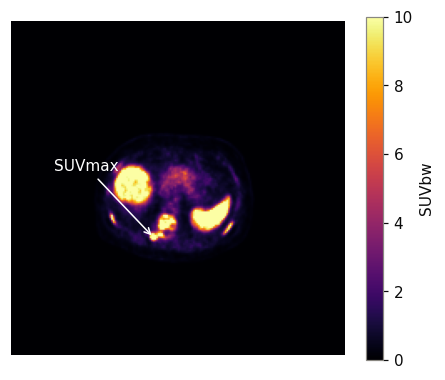

In [24]:
fig, ax = plt.subplots(figsize=(4.2, 4.2))
im = ax.imshow(suv[k[0]], cmap="inferno", vmin=0, vmax=10)
ax.annotate("SUVmax", xy=(k[2], k[1]), xytext=(k[2] - 60, k[1] - 40), color="white", arrowprops=dict(arrowstyle="->", color="white"))
ax.axis("off"); plt.colorbar(im, ax=ax, shrink=0.8, label="SUVbw"); plt.tight_layout(); plt.show()

In [25]:
zs = np.array([float(d.ImagePositionPatient[2]) for d in pt])

def suv_at(z, x, y):
    k = int(np.argmin(np.abs(zs - z)))
    return suv[k, int(round(y)), int(round(x))]

print(suv_at(-471.5, 100, 100))

2.065830321434714


In [26]:
def suv_wrong(d):
    return d.pixel_array.astype(float) * float(d.RescaleSlope) * weight_g / dose

suv2 = np.stack([suv_wrong(d) for d in pt])
print(f"SUVmax = {suv2.max():.2f}")


SUVmax = 21.32


In [27]:
def suv_wrong(d):
    return d.pixel_array.astype(float) * float(d.RescaleSlope) * weight_g / dose_at_scan

suv2 = np.stack([suv_wrong(d) for d in pt])
print(f"SUVmax = {suv2.max():.2f}")

SUVmax = 29.52


In [28]:
def affine(ds, k_spacing):
    iop = np.array(ds.ImageOrientationPatient, dtype=float)
    r, c = iop[:3], iop[3:]
    n = np.cross(r, c)
    ps = [float(v) for v in ds.PixelSpacing]
    M = np.eye(4)
    M[:3, 0] = r * ps[1]
    M[:3, 1] = c * ps[0]
    M[:3, 2] = n * k_spacing
    M[:3, 3] = np.array(ds.ImagePositionPatient, dtype=float)
    return M

def sort_by_position(series):
    iop = np.array(series[0].ImageOrientationPatient, dtype=float)
    n = np.cross(iop[:3], iop[3:])
    pos = [float(np.dot(n, np.array(d.ImagePositionPatient, dtype=float))) for d in series]
    order = np.argsort(pos)
    return [series[i] for i in order], np.array(pos)[order]

In [29]:
rows = []
for name in ["ct-psma", "pet-psma", "ct-hcc", "mr-lgg"]:
    series = read_dir(name)
    if name == "mr-lgg":
        series = [d for d in series if d.SeriesDescription == series[0].SeriesDescription]
    s, pos = sort_by_position(series)
    rows.append({"series": name, "slices": len(s), "SliceThickness": float(s[0].SliceThickness),
                 "SpacingBetweenSlices": s[0].get("SpacingBetweenSlices", "—"),
                 "measured spacing (mm)": sorted(set(np.round(np.diff(pos), 2).tolist()))})
pd.DataFrame(rows)

,series,slices,SliceThickness,SpacingBetweenSlices,measured spacing (mm)
0,ct-psma,12,3.0,—,[3.0]
1,pet-psma,40,3.0,—,[2.0]
2,ct-hcc,36,5.0,—,[5.0]
3,mr-lgg,3,3.0,3.0,"[6.0, 24.0]"


In [30]:
ct_series, ct_pos = sort_by_position(read_dir("ct-psma"))
d0 = ct_series[0]
ps = [float(v) for v in d0.PixelSpacing]
x_mm = ps[1] * d0.Columns
y_mm = ps[0] * d0.Rows
z_mm = ct_pos[-1] - ct_pos[0]
print(f"x（列方向）: {ps[1]:.3f} mm × {d0.Columns} = {x_mm:.1f} mm")
print(f"y（行方向）: {ps[0]:.3f} mm × {d0.Rows} = {y_mm:.1f} mm")
print(f"z（スライス方向）: {ct_pos[0]:.1f} 〜 {ct_pos[-1]:.1f} mm = {z_mm:.1f} mm")

x（列方向）: 0.977 mm × 512 = 500.0 mm
y（行方向）: 0.977 mm × 512 = 500.0 mm
z（スライス方向）: -491.5 〜 -458.5 mm = 33.0 mm


In [31]:
series = read_dir("ct-hcc")
series.sort(key=lambda d: int(d.InstanceNumber))
z = [float(d.ImagePositionPatient[2]) for d in series]
print("z の間隔の平均:", np.diff(z).mean(), "mm")
print(np.diff(z))

z の間隔の平均: -4.714285714285714 mm
[ -5. -15.  -5. -15. -15.  -5.  -5.  -5. -10. -20.  -5.  -5.  -5.  -5.
 130.  -5. -15.  -5. -15.  -5. -10.  -5. -25. -10.  -5.  -5. -30.  -5.
  -5.  -5.  -5.  -5.  -5.  -5.  -5.]


In [32]:
series = read_dir("ct-hcc")
s, pos = sort_by_position(series)
print("z の間隔の平均:", np.diff(pos).mean(), "mm")
print(np.diff(pos))

z の間隔の平均: 5.0 mm
[5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5.
 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5.]


In [33]:
ptS, ptPos = sort_by_position(pt)
ctS, ctPos = sort_by_position(ct)
print("同じ座標系か:", ptS[0].FrameOfReferenceUID == ctS[0].FrameOfReferenceUID)

zc = ctPos[len(ctPos) // 2]
ic = int(np.argmin(np.abs(ctPos - zc))); ip = int(np.argmin(np.abs(ptPos - zc)))
M_pt = affine(ptS[0], k_spacing=float(np.diff(ptPos).mean()))
M_ct = affine(ctS[0], k_spacing=float(np.diff(ctPos).mean()))
p = M_pt @ np.array([100, 100, ip, 1.0])
print(f"PET 画素 (列100, 行100, スライス{ip}) →", np.round(p[:3], 1), "mm")
back = np.linalg.inv(M_pt) @ p
print("戻した添え字:", np.round(back[:3], 6))
q = np.linalg.inv(M_ct) @ p
print("同じ位置の CT 画素 (列, 行, スライス) =", np.round(q[:3], 1))

同じ座標系か: True
PET 画素 (列100, 行100, スライス20) → [   0.9 -197.9 -473.5] mm
戻した添え字: [100. 100.  20.]
同じ位置の CT 画素 (列, 行, スライス) = [256.4 257.2   6. ]


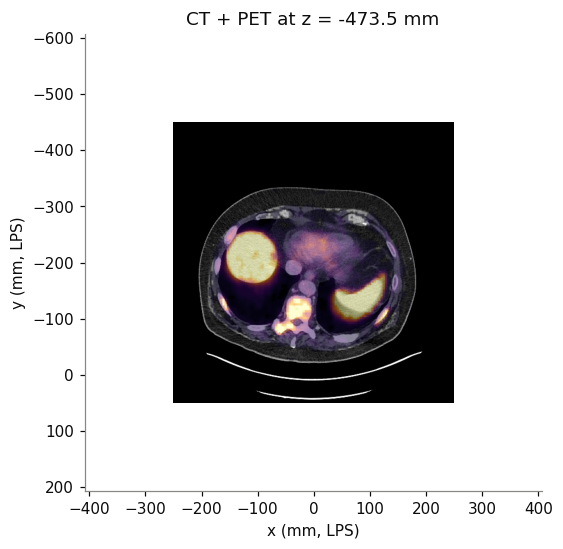

In [34]:
def extent(M, shape):
    x0, y0 = (M @ np.array([-0.5, -0.5, 0, 1]))[:2]; x1, y1 = (M @ np.array([shape[1] - 0.5, shape[0] - 0.5, 0, 1]))[:2]
    return [x0, x1, y1, y0]

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ct_hu = ctS[ic].pixel_array.astype(float) * float(ctS[ic].RescaleSlope) + float(ctS[ic].RescaleIntercept)
ax.imshow(ct_hu, cmap="gray", vmin=-160, vmax=240, extent=extent(M_ct, ct_hu.shape))
ax.imshow(np.ma.masked_less(suv[ip], 0.5), cmap="inferno", vmin=0, vmax=10, alpha=0.5, extent=extent(M_pt, suv[ip].shape))
ax.set_xlabel("x (mm, LPS)"); ax.set_ylabel("y (mm, LPS)"); ax.set_title(f"CT + PET at z = {zc:.1f} mm")
plt.tight_layout(); plt.show()


In [35]:
def resample(M_target, shape, vol, M_src, order):
    K, I, J = np.indices(shape)
    idx = np.stack([J, I, K, np.ones_like(J)]).reshape(4, -1).astype(float)
    mm = M_target @ idx
    src = np.linalg.inv(M_src) @ mm
    out = map_coordinates(vol, [src[2], src[1], src[0]], order=order, mode="constant", cval=np.nan)
    return out.reshape(shape)

ct_vol = np.stack([d.pixel_array.astype(float) * float(d.RescaleSlope) + float(d.RescaleIntercept) for d in ctS])
suv_nn = resample(M_ct, ct_vol.shape, suv, M_pt, order=0)
suv_li = resample(M_ct, ct_vol.shape, suv, M_pt, order=1)
print("CT の格子:", ct_vol.shape, "/ PET の格子:", suv.shape, "/ 範囲外（NaN）の画素:", int(np.isnan(suv_nn).sum()), int(np.isnan(suv_li).sum()))

CT の格子: (12, 512, 512) / PET の格子: (40, 200, 200) / 範囲外（NaN）の画素: 0 0


In [36]:
back = resample(M_pt, suv.shape, suv, M_pt, order=1)
print("PET → PET の最大の差:", np.abs(back - suv).max())

print(f"SUVmax  PET の格子: {suv.max():.2f} / CT の格子（最近傍）: {np.nanmax(suv_nn):.2f} / CT の格子（線形）: {np.nanmax(suv_li):.2f}  （線形は {np.nanmax(suv_li) / suv.max() * 100:.1f}%）")
body = ct_vol > -300
print(f"体の中の SUV の平均  最近傍: {np.nanmean(suv_nn[body]):.3f} / 線形: {np.nanmean(suv_li[body]):.3f}")

def body_dice(pet_on_ct):
    ok = ~np.isnan(pet_on_ct)
    a = body & ok; b = (np.nan_to_num(pet_on_ct) > 0.5) & ok
    return 2 * (a & b).sum() / (a.sum() + b.sum())
print(f"体の一致（Dice）  最近傍: {body_dice(suv_nn):.3f} / 線形: {body_dice(suv_li):.3f}")

PET → PET の最大の差: 4.360956040727615e-13
SUVmax  PET の格子: 29.52 / CT の格子（最近傍）: 29.52 / CT の格子（線形）: 28.89  （線形は 97.9%）
体の中の SUV の平均  最近傍: 2.590 / 線形: 2.617
体の一致（Dice）  最近傍: 0.722 / 線形: 0.723


In [37]:
ct_on_pet = resample(M_pt, suv.shape, ct_vol, M_ct, order=1)
valid_slices = np.sum([not np.all(np.isnan(ct_on_pet[k])) for k in range(ct_on_pet.shape[0])])
nan_ratio = np.isnan(ct_on_pet).mean()
print(f"値が入っているスライスの枚数: {valid_slices} / {ct_on_pet.shape[0]}")
print(f"NaN の割合: {nan_ratio:.3f}")

値が入っているスライスの枚数: 17 / 40
NaN の割合: 0.841


In [38]:
K, I, J = np.indices(ct_vol.shape)
wrong = map_coordinates(suv, [K * suv.shape[0] / ct_vol.shape[0],
                              I * suv.shape[1] / ct_vol.shape[1],
                              J * suv.shape[2] / ct_vol.shape[2]], order=1, mode="constant", cval=np.nan)
print(f"体の一致（Dice）: {body_dice(wrong):.3f}")

体の一致（Dice）: 0.373


In [39]:
fixed = resample(M_ct, ct_vol.shape, suv, M_pt, order=1)
print(f"体の一致（Dice）: {body_dice(fixed):.3f}")

体の一致（Dice）: 0.723
